# Imports

In [4]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from typing import Tuple, Dict, Any

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    f1_score,
    precision_score,
    recall_score,
    log_loss,
    mean_squared_error
)
from scipy import stats

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
import xgboost as xgb

import optuna


import shap
_HAS_SHAP = True


RANDOM_STATE = 2025

# Helper functions

In [6]:
def load_and_preprocess_data(file_path: str) -> pd.DataFrame:
    df = pd.read_csv(file_path)
    df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
    df = df.dropna(subset=['TotalCharges'])
    if 'SeniorCitizen' in df.columns:
        df['SeniorCitizen'] = df['SeniorCitizen'].map({0: 'No', 1: 'Yes'})
    return df


def define_feature_sets(df: pd.DataFrame) -> Tuple[list, list]:
    categorical_columns = [
        'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
        'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
        'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
        'PaperlessBilling', 'PaymentMethod'
    ]
    numeric_columns = ['tenure', 'MonthlyCharges', 'TotalCharges']
    missing_cat = [c for c in categorical_columns if c not in df.columns]
    missing_num = [c for c in numeric_columns if c not in df.columns]
    if missing_cat or missing_num:
        raise ValueError(f"Colunas ausentes no dataset. Categóricas faltando: {missing_cat}; Numéricas faltando: {missing_num}")
    return categorical_columns, numeric_columns


def create_preprocessor(categorical_columns, numeric_columns) -> ColumnTransformer:
    return ColumnTransformer(
        transformers=[
            ('cat', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), categorical_columns),
            ('num', StandardScaler(), numeric_columns)
        ]
    )


def calculate_ks_statistic(y_true: np.ndarray, y_proba: np.ndarray):
    class_0_proba = y_proba[y_true == 0]
    class_1_proba = y_proba[y_true == 1]
    ks_stat, p_value = stats.ks_2samp(class_0_proba, class_1_proba)
    return ks_stat, p_value


def compute_metrics(model, X, y, dataset_name='dataset') -> Dict[str, Any]:
    y_probs = model.predict_proba(X)[:, 1]
    y_pred = model.predict(X)

    mse = mean_squared_error(y, y_probs)
    ce = log_loss(y, y_probs)
    cm = confusion_matrix(y, y_pred)
    auroc = roc_auc_score(y, y_probs)
    precision = precision_score(y, y_pred)
    recall = recall_score(y, y_pred)
    f1 = f1_score(y, y_pred)
    ks_stat, ks_pvalue = calculate_ks_statistic(y, y_probs)

    print(f"--- Métricas para {dataset_name} ---")
    print(f"MSE: {mse:.4f}")
    print(f"Cross-Entropy (Log Loss): {ce:.4f}")
    print(f"AUROC: {auroc:.4f}")
    print(f"KS Estatística: {ks_stat:.4f} (p-valor: {ks_pvalue:.4f})")
    print(f"Precisão: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1-Score: {f1:.4f}")
    print("Matriz de Confusão:")
    print(cm)
    print(classification_report(y, y_pred, digits=4))

    return {
        'mse': mse,
        'cross_entropy': ce,
        'auroc': auroc,
        'ks_stat': ks_stat,
        'ks_p_value': ks_pvalue,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'confusion_matrix': cm
    }


def plot_evaluations(model, X, y, dataset_name='Dataset'):
    y_probs = model.predict_proba(X)[:, 1]
    y_pred = model.predict(X)
    cm = confusion_matrix(y, y_pred)

    fpr, tpr, _ = roc_curve(y, y_probs)
    plt.figure(figsize=(6, 5))
    plt.plot(fpr, tpr, label=f'ROC AUC = {roc_auc_score(y, y_probs):.3f}')
    plt.plot([0, 1], [0, 1], 'k--')
    plt.xlabel('FPR'); plt.ylabel('TPR'); plt.title(f'Curva ROC - {dataset_name}')
    plt.legend(); plt.grid(True); plt.show()

    prec, rec, _ = precision_recall_curve(y, y_probs)
    plt.figure(figsize=(6, 5))
    plt.plot(rec, prec, label='Precision-Recall')
    plt.xlabel('Recall'); plt.ylabel('Precision'); plt.title(f'Curva PR - {dataset_name}')
    plt.legend(); plt.grid(True); plt.show()

    probs_0 = y_probs[y == 0]; probs_1 = y_probs[y == 1]
    all_probs = np.sort(np.concatenate([probs_0, probs_1]))
    cdf_0 = np.searchsorted(probs_0, all_probs, side='right') / len(probs_0)
    cdf_1 = np.searchsorted(probs_1, all_probs, side='right') / len(probs_1)
    ks_statistic = np.max(np.abs(cdf_0 - cdf_1))
    plt.figure(figsize=(6, 5))
    plt.plot(all_probs, cdf_0, label='CDF Classe 0')
    plt.plot(all_probs, cdf_1, label='CDF Classe 1')
    plt.vlines(all_probs[np.argmax(np.abs(cdf_0 - cdf_1))], ymin=min(cdf_0), ymax=max(cdf_1),
               colors='red', linestyles='dashed', label=f'KS = {ks_statistic:.3f}')
    plt.xlabel('Probabilidades'); plt.ylabel('CDF'); plt.title(f'Curva KS - {dataset_name}')
    plt.legend(); plt.grid(True); plt.show()

    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['No', 'Yes'], yticklabels=['No', 'Yes'])
    plt.ylabel('Real'); plt.xlabel('Predito'); plt.title(f'Matriz de Confusão - {dataset_name}')
    plt.show()


def make_pipeline(preprocessor: ColumnTransformer, trial: optuna.trial.Trial) -> ImbPipeline:
    xgb_n_estimators = trial.suggest_int('xgb_n_estimators', 100, 1000, step=50)
    xgb_max_depth = trial.suggest_int('xgb_max_depth', 3, 12)
    xgb_learning_rate = trial.suggest_float('xgb_learning_rate', 0.01, 0.3, log=True)
    xgb_subsample = trial.suggest_float('xgb_subsample', 0.5, 1.0)
    xgb_colsample_bytree = trial.suggest_float('xgb_colsample_bytree', 0.5, 1.0)
    xgb_gamma = trial.suggest_float('xgb_gamma', 0.0, 5.0)

    classifier = xgb.XGBClassifier(
        n_estimators=xgb_n_estimators,
        max_depth=xgb_max_depth,
        learning_rate=xgb_learning_rate,
        subsample=xgb_subsample,
        colsample_bytree=xgb_colsample_bytree,
        gamma=xgb_gamma,
        eval_metric='logloss',
        tree_method='hist',
        random_state=RANDOM_STATE,
        n_jobs=-1
    )

    smote_k = trial.suggest_int('smote_k_neighbors', 3, 10)

    pipe = ImbPipeline(steps=[
        ('preprocessor', preprocessor),
        ('smote', SMOTE(random_state=RANDOM_STATE, k_neighbors=smote_k)),
        ('classifier', classifier)
    ])
    return pipe


def tune_with_optuna(X_train: pd.DataFrame, y_train: pd.Series,
                     preprocessor: ColumnTransformer,
                     n_trials: int = 40, cv_splits: int = 5,
                     timeout: int | None = None) -> Tuple[ImbPipeline, optuna.Study]:
    def objective(trial: optuna.trial.Trial) -> float:
        pipeline = make_pipeline(preprocessor, trial)
        cv = StratifiedKFold(n_splits=cv_splits, shuffle=True, random_state=RANDOM_STATE)
        scores = cross_val_score(pipeline, X_train, y_train, cv=cv, scoring='roc_auc', n_jobs=-1)
        return float(np.mean(scores))

    study = optuna.create_study(direction='maximize')
    study.optimize(objective, n_trials=n_trials, timeout=timeout, show_progress_bar=True)

    print("Melhores parâmetros (Optuna):", study.best_trial.params)
    best_trial = study.best_trial
    best_pipeline = make_pipeline(preprocessor, best_trial)
    best_pipeline.fit(X_train, y_train)

    return best_pipeline, study


def shap_summary_for_model(pipeline: ImbPipeline,
                           X_reference: pd.DataFrame,
                           categorical_columns: list,
                           numeric_columns: list,
                           max_background: int = 800,
                           max_display: int = 20):
    if not _HAS_SHAP:
        print("SHAP não está instalado. Instale com: pip install shap")
        return

    preprocessor: ColumnTransformer = pipeline.named_steps['preprocessor']
    clf = pipeline.named_steps['classifier']

    ohe: OneHotEncoder = preprocessor.named_transformers_['cat']
    ohe_feature_names = list(ohe.get_feature_names_out(categorical_columns))
    feature_names = ohe_feature_names + numeric_columns

    X_proc = preprocessor.transform(X_reference)
    if isinstance(X_proc, np.ndarray):
        X_proc_df = pd.DataFrame(X_proc, columns=feature_names)
    else:
        X_proc_df = pd.DataFrame(X_proc.toarray(), columns=feature_names)

    if len(X_proc_df) > max_background:
        X_bg = X_proc_df.sample(n=max_background, random_state=RANDOM_STATE)
    else:
        X_bg = X_proc_df

    explainer = shap.TreeExplainer(clf)
    shap_values = explainer.shap_values(X_bg)

    plt.figure()
    try:
        shap.summary_plot(shap_values[1] if isinstance(shap_values, list) else shap_values,
                          X_bg, feature_names=feature_names, show=False, max_display=max_display)
    except Exception:
        shap.summary_plot(shap_values, X_bg, feature_names=feature_names, show=False, max_display=max_display)
    plt.title('SHAP Summary (Validação)')
    plt.show()

    plt.figure()
    try:
        shap.summary_plot(shap_values[1] if isinstance(shap_values, list) else shap_values,
                          X_bg, feature_names=feature_names, show=False, plot_type='bar', max_display=max_display)
    except Exception:
        shap.summary_plot(shap_values, X_bg, feature_names=feature_names, show=False, plot_type='bar', max_display=max_display)
    plt.title('SHAP Feature Importance (Bar)')
    plt.show()


# Pipeline

In [8]:

def main(file_path: str | None = None,
         n_trials: int | None = None,
         cv_splits: int = 5) -> Dict[str, Any]:
    print("INICIANDO PIPELINE COM SMOTE + OPTUNA + SHAP")
    print("=" * 80)

    if file_path is None:
        candidates = [
            '../_data/customer_churn_telecom_services.csv',
            '../../_data/customer_churn_telecom_services.csv',
            '../../../_data/customer_churn_telecom_services.csv',
            'notebooks/_data/customer_churn_telecom_services.csv',
            '_data/customer_churn_telecom_services.csv'
        ]
        for c in candidates:
            if os.path.exists(c):
                file_path = c
                break
        if file_path is None:
            file_path = '../_data/customer_churn_telecom_services.csv'

    df = load_and_preprocess_data(file_path)
    if set(df['Churn'].unique()) == {'Yes', 'No'}:
        y = df['Churn'].map({'No': 0, 'Yes': 1})
    else:
        y = df['Churn']
    categorical_columns, numeric_columns = define_feature_sets(df)
    X = df.drop(columns='Churn')

    X_train, X_temp, y_train, y_temp = train_test_split(
        X, y, test_size=0.50, random_state=RANDOM_STATE, stratify=y
    )
    X_test, X_val, y_test, y_val = train_test_split(
        X_temp, y_temp, test_size=0.50, random_state=RANDOM_STATE, stratify=y_temp
    )
    print("\nTamanhos dos conjuntos:")
    print(f"Treino: {X_train.shape[0]} | Validação: {X_val.shape[0]} | Teste: {X_test.shape[0]}")
    print(f"Distribuição no treino: {y_train.value_counts().to_dict()}")
    print(f"Distribuição na validação: {y_val.value_counts().to_dict()}")
    print(f"Distribuição no teste: {y_test.value_counts().to_dict()}")

    preprocessor = create_preprocessor(categorical_columns, numeric_columns)

    if n_trials is None:
        n_trials = int(os.getenv("OPTUNA_TRIALS", "40"))

    print(f"\nOtimizando hiperparâmetros com Optuna (n_trials={n_trials}, cv={cv_splits})...")
    best_pipeline, study = tune_with_optuna(
        X_train=X_train, y_train=y_train, preprocessor=preprocessor,
        n_trials=n_trials, cv_splits=cv_splits
    )

    print("\nAvaliação no conjunto de Validação:")
    val_metrics = compute_metrics(best_pipeline, X_val, y_val, dataset_name='Validação')
    plot_evaluations(best_pipeline, X_val, y_val, dataset_name='Validação')

    print("\nAvaliação no conjunto de Teste:")
    test_metrics = compute_metrics(best_pipeline, X_test, y_test, dataset_name='Teste')
    plot_evaluations(best_pipeline, X_test, y_test, dataset_name='Teste')

    print("\nGerando explicações SHAP no conjunto de Validação...")
    shap_summary_for_model(
        best_pipeline, X_val,
        categorical_columns=categorical_columns,
        numeric_columns=numeric_columns,
        max_background=800, max_display=20
    )

    print("\nPIPELINE CONCLUÍDO!")
    return {
        'pipeline': best_pipeline,
        'optuna_study': study,
        'val_metrics': val_metrics,
        'test_metrics': test_metrics,
        'splits': (X_train, y_train, X_val, y_val, X_test, y_test),
        'features': {
            'categorical': categorical_columns,
            'numeric': numeric_columns
        }
    }


[I 2025-08-11 12:39:34,010] A new study created in memory with name: no-name-ed43398d-a301-45b9-9c71-a168c953cd5b


INICIANDO PIPELINE COM SMOTE + OPTUNA + SHAP

Tamanhos dos conjuntos:
Treino: 3516 | Validação: 1758 | Teste: 1758
Distribuição no treino: {0: 2581, 1: 935}
Distribuição na validação: {0: 1291, 1: 467}
Distribuição no teste: {0: 1291, 1: 467}

Otimizando hiperparâmetros com Optuna (n_trials=40, cv=5)...


Best trial: 0. Best value: 0.837277:   2%|▎         | 1/40 [00:01<01:05,  1.68s/it]

[I 2025-08-11 12:39:35,692] Trial 0 finished with value: 0.8372768297966153 and parameters: {'xgb_n_estimators': 900, 'xgb_max_depth': 11, 'xgb_learning_rate': 0.025700189535906103, 'xgb_subsample': 0.7290147600039206, 'xgb_colsample_bytree': 0.557000993114841, 'xgb_gamma': 2.3684371444226455, 'smote_k_neighbors': 8}. Best is trial 0 with value: 0.8372768297966153.


Best trial: 1. Best value: 0.837957:   5%|▌         | 2/40 [00:02<00:51,  1.36s/it]

...

[I 2025-08-11 12:39:49,715] Trial 36 finished with value: 0.8384361305626523 and parameters: {'xgb_n_estimators': 600, 'xgb_max_depth': 4, 'xgb_learning_rate': 0.033178238255447565, 'xgb_subsample': 0.6237575604231254, 'xgb_colsample_bytree': 0.9065051866745142, 'xgb_gamma': 3.4673425855339968, 'smote_k_neighbors': 9}. Best is trial 16 with value: 0.8415795667128597.


Best trial: 16. Best value: 0.84158:  98%|█████████▊| 39/40 [00:16<00:00,  3.28it/s]

[I 2025-08-11 12:39:50,289] Trial 37 finished with value: 0.8401611831241098 and parameters: {'xgb_n_estimators': 700, 'xgb_max_depth': 5, 'xgb_learning_rate': 0.01370673076459723, 'xgb_subsample': 0.578999641488644, 'xgb_colsample_bytree': 0.7740135487866512, 'xgb_gamma': 3.2109441300407315, 'smote_k_neighbors': 10}. Best is trial 16 with value: 0.8415795667128597.
[I 2025-08-11 12:39:50,458] Trial 38 finished with value: 0.8346339472646271 and parameters: {'xgb_n_estimators': 500, 'xgb_max_depth': 3, 'xgb_learning_rate': 0.2747112213974745, 'xgb_subsample': 0.5313697749158623, 'xgb_colsample_bytree': 0.6218998752943377, 'xgb_gamma': 4.532707122175409, 'smote_k_neighbors': 4}. Best is trial 16 with value: 0.8415795667128597.


Best trial: 16. Best value: 0.84158: 100%|██████████| 40/40 [00:16<00:00,  2.38it/s]


[I 2025-08-11 12:39:50,810] Trial 39 finished with value: 0.8410448093591267 and parameters: {'xgb_n_estimators': 550, 'xgb_max_depth': 4, 'xgb_learning_rate': 0.017203586074683745, 'xgb_subsample': 0.9611569895040355, 'xgb_colsample_bytree': 0.6331663123982277, 'xgb_gamma': 3.745706783836839, 'smote_k_neighbors': 8}. Best is trial 16 with value: 0.8415795667128597.
Melhores parâmetros (Optuna): {'xgb_n_estimators': 500, 'xgb_max_depth': 3, 'xgb_learning_rate': 0.026649007222086234, 'xgb_subsample': 0.5974020365558523, 'xgb_colsample_bytree': 0.7269386806634801, 'xgb_gamma': 3.9399236453269273, 'smote_k_neighbors': 3}

Avaliação no conjunto de Validação:
--- Métricas para Validação ---
MSE: 0.1459
Cross-Entropy (Log Loss): 0.4394
AUROC: 0.8443
KS Estatística: 0.5326 (p-valor: 0.0000)
Precisão: 0.5627
Recall: 0.6916
F1-Score: 0.6206
Matriz de Confusão:
[[1040  251]
 [ 144  323]]
              precision    recall  f1-score   support

           0     0.8784    0.8056    0.8404      1291


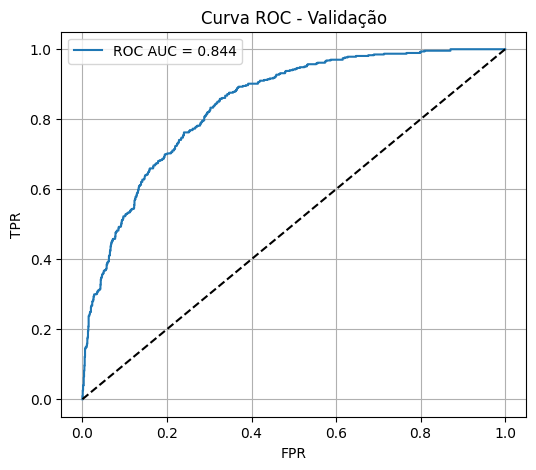

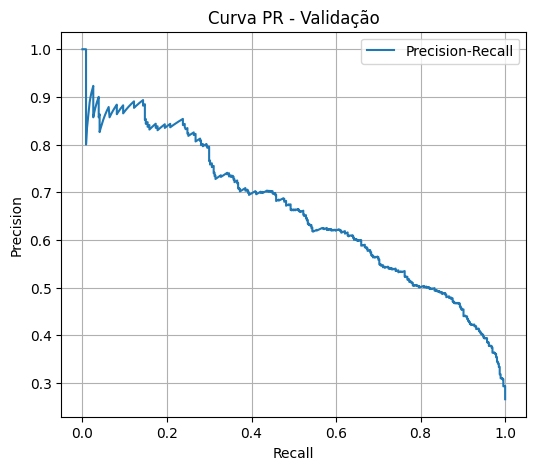

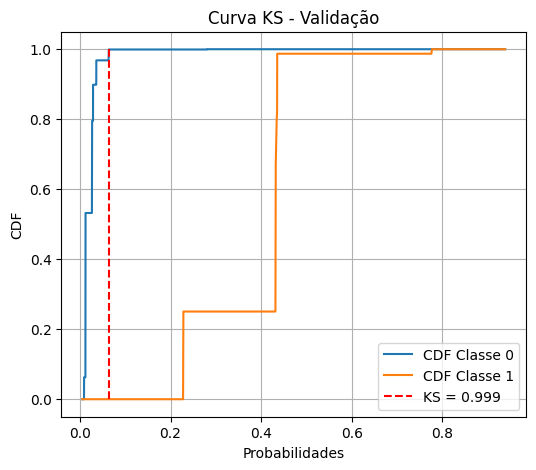

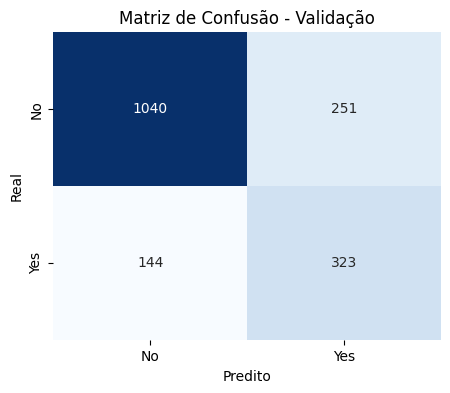


Avaliação no conjunto de Teste:
--- Métricas para Teste ---
MSE: 0.1380
Cross-Entropy (Log Loss): 0.4256
AUROC: 0.8513
KS Estatística: 0.5595 (p-valor: 0.0000)
Precisão: 0.6011
Recall: 0.6938
F1-Score: 0.6441
Matriz de Confusão:
[[1076  215]
 [ 143  324]]
              precision    recall  f1-score   support

           0     0.8827    0.8335    0.8574      1291
           1     0.6011    0.6938    0.6441       467

    accuracy                         0.7964      1758
   macro avg     0.7419    0.7636    0.7508      1758
weighted avg     0.8079    0.7964    0.8007      1758



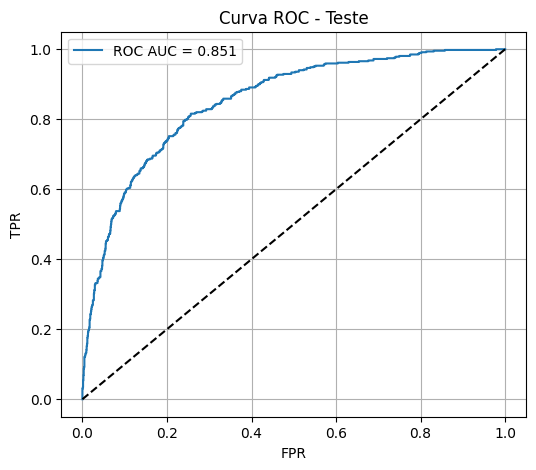

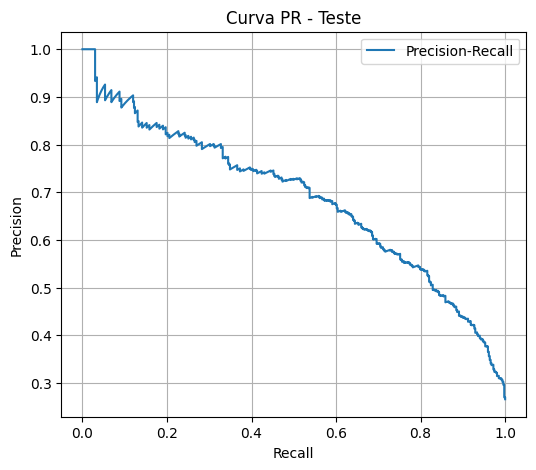

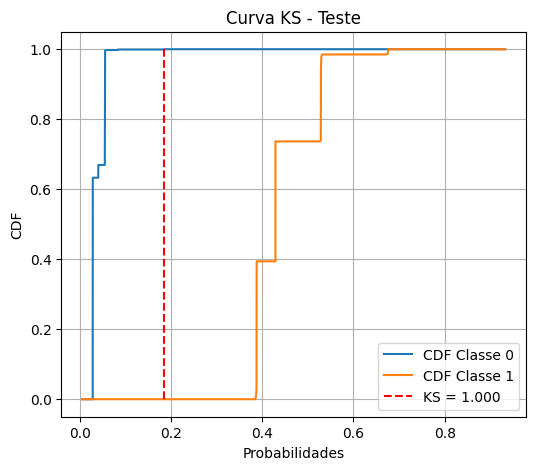

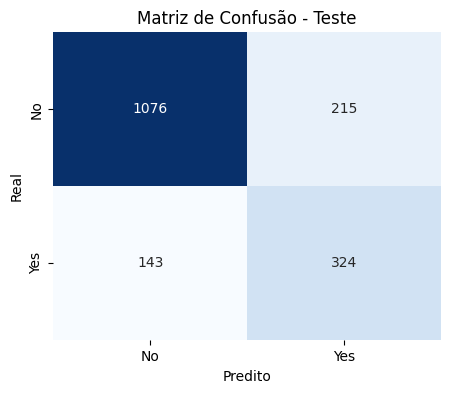


Gerando explicações SHAP no conjunto de Validação...


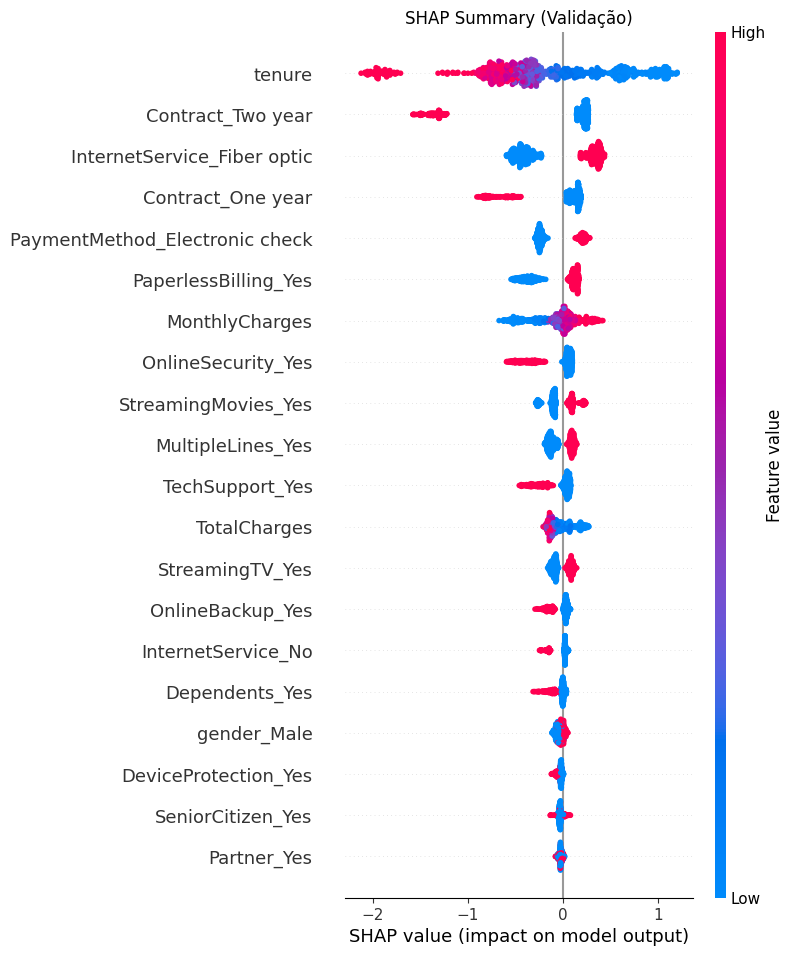

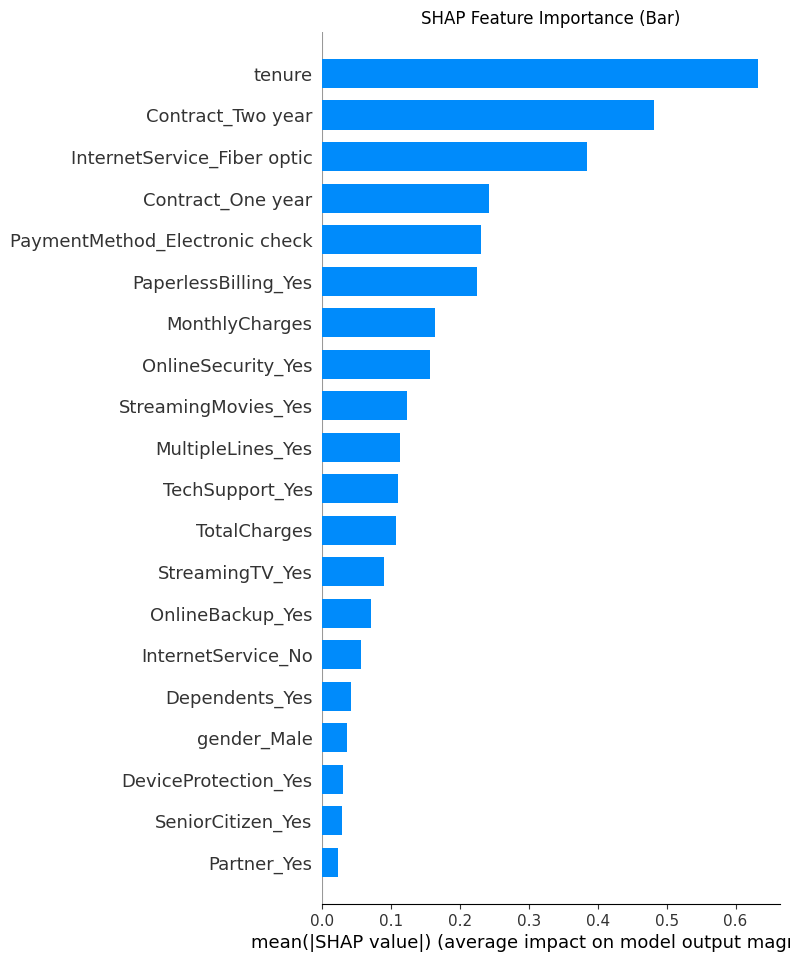


PIPELINE CONCLUÍDO!


In [9]:
if __name__ == "__main__":
    _ = main()